In [73]:
import torch
import scipy.stats
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
sns.set_style("darkgrid")  # Set the style of the plots

In [2]:
# PI_0 -> Simple Distribution, Gaussian
# PI_1

In [15]:
mu = 1
sigma = 5. - 0.5 * mu
z = torch.randn(1, 100_000) * sigma + mu


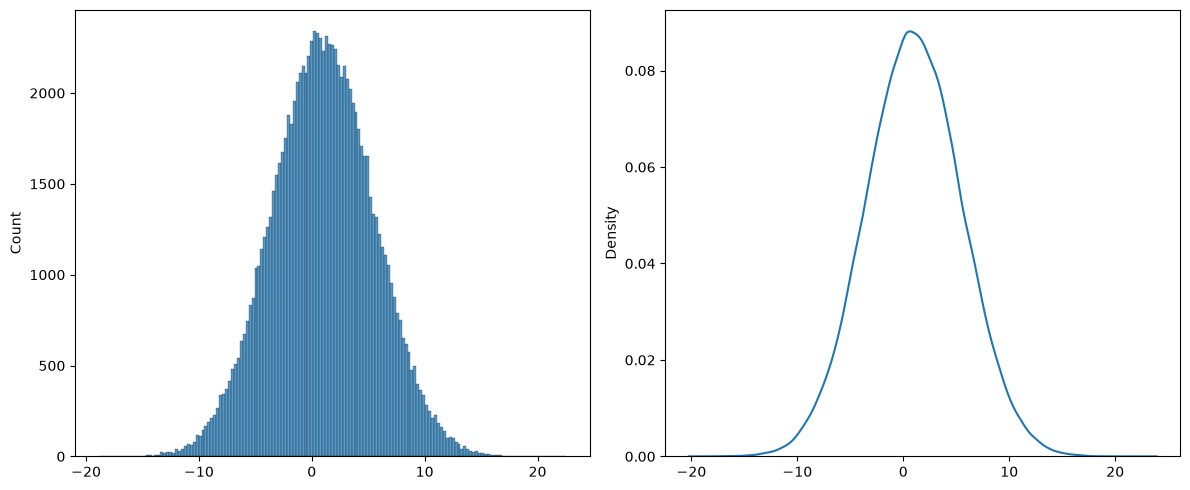

In [17]:
f, axes = plt.subplots(1, 2, figsize=(12, 5))


sns.histplot(z[0], ax=axes[0])
sns.kdeplot(z[0], ax=axes[1])

f.tight_layout()


In [36]:
mixture_prob = np.array([0.55, 0.45], dtype=float)  # Mixture weights
mixture_mus = np.array([-0.85, 1.5], dtype=float)  # Means of the two Gaussian modes
mixture_sigmas = np.array([0.65, 0.25], dtype=float)  # Standard deviations of the modes

def mixture_pdf(x: np.ndarray) -> np.ndarray:
    """Compute the PDF of a mixture of Gaussians."""
    comps = scipy.stats.norm.pdf(x[None, :], loc=mixture_mus[:, None], scale=mixture_sigmas[:, None])
    return np.sum(mixture_prob[:, None] * comps, axis=0)

def mixture_sample(size: int) -> np.ndarray:
    """Sample from a mixture of Gaussians."""
    rand_idx = np.random.choice(range(len(mixture_prob)), size=size, p=mixture_prob)
    means = mixture_mus[rand_idx]
    stds = mixture_sigmas[rand_idx]
    return np.random.normal(loc=means, scale=stds)

/var/folders/d_/r89f0qt56b91xr3wj5bwft480000gr/T/ipykernel_16397/1298721437.py:16: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


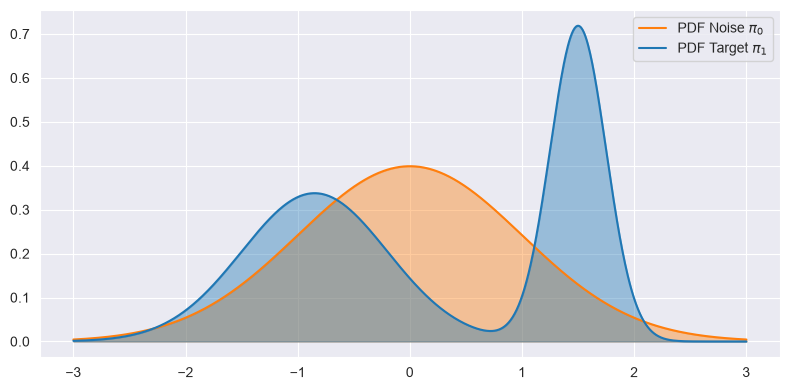

In [39]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), constrained_layout=True, dpi=100)

x_all_steps = np.linspace(-3, 3, 1000)

pdf_noise = scipy.stats.norm.pdf(x_all_steps, loc=0, scale=1)
ax.plot(x_all_steps, pdf_noise, label=r"PDF Noise $\pi_0$", color="tab:orange")
ax.fill_between(x_all_steps, pdf_noise, alpha=0.4, color="tab:orange")


pdf_target = mixture_pdf(x=x_all_steps)
ax.plot(x_all_steps, pdf_target, label=r"PDF Target $\pi_1$", color="tab:blue")
ax.fill_between(x_all_steps, pdf_target, alpha=0.4, color="tab:blue")


plt.legend()
plt.tight_layout()


In [40]:
def interpolate_linear(x_0, x_1, t):
    """Evaluates the linear interpolation path between x_0 and x_1 at step t."""
    x_t = ((1 - t) * x_0) + (t * x_1)
    return x_t

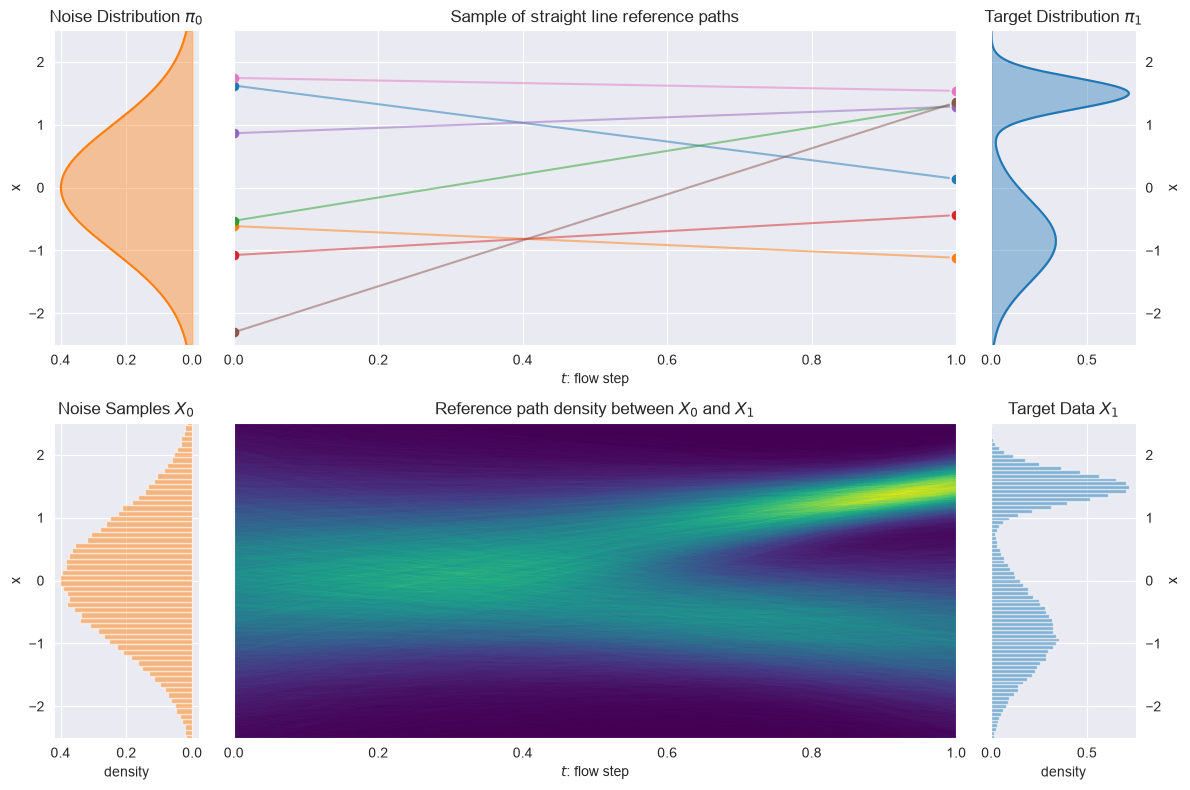

In [69]:
# Illustration of the sampled reference paths
# Set up the plot
fig, ((ax11, ax12, ax13), (ax21, ax22, ax23)) = plt.subplots(
    2,
    3,
    figsize=(12, 8),
    gridspec_kw={"width_ratios": [1, 5, 1]},
    sharey=True,
    dpi=100,
)
fig.subplots_adjust(wspace=0)
x_min, x_max = -2.5, 2.5
x_all_steps = np.linspace(x_min, x_max, 1000)

# Sample set of noise and target points
data_size: int = 100_000
np.random.seed(1)  # Set random seeds for reproducibility
data_x_0 = np.random.randn(data_size)
data_x_1 = mixture_sample(size=data_size)

# Plot a few sample paths ##########################################
# Plot Noise distribution π₀
ax11.set_title(r"Noise Distribution $\pi_0$")
pdf_noise = scipy.stats.norm.pdf(x_all_steps, loc=0, scale=1)
ax11.plot(pdf_noise, x_all_steps, label=r"PDF Noise $\pi_0$", color="tab:orange")
ax11.fill_betweenx(x_all_steps, pdf_noise, alpha=0.4, color="tab:orange")
ax11.invert_xaxis()
ax11.set_ylabel("x")
ax11.set_xlabel("")
# ax11.set_xlim(0, 1)

# Plot final distribution x1
ax13.set_title(r"Target Distribution $\pi_1$")
pdf_target = mixture_pdf(x=x_all_steps)
ax13.plot(pdf_target, x_all_steps, label=r"PDF Target $\pi_1$", color="tab:blue")
ax13.fill_betweenx(x_all_steps, pdf_target, alpha=0.4, color="tab:blue")
ax13.set_xlabel("")
ax13.yaxis.set_label_position("right")
ax13.set_ylabel("x")
# Also show y-axis values on the right side
ax13.yaxis.set_visible(True)
ax13.yaxis.set_tick_params(labelright=True)
# ax13.set_xlim(0, 1)

# Plot the Sample paths
nb_samples = 7
t = np.arange(0, 1, 0.01)
ax12.set_title("Sample of straight line reference paths")
colors = plt.cm.tab10.colors
for i in range(nb_samples):
    color = colors[i % len(colors)]
    ax12.plot(t, interpolate_linear(x_0=data_x_0[i], x_1=data_x_1[i], t=t), alpha=0.5, color=color)
    ax12.scatter([0, 1], [data_x_0[i], data_x_1[i]], color=color)
ax12.set_ylim(x_min, x_max)
ax12.set_xlim(0, 1)
ax12.set_xlabel("$t$: flow step")


# Plot the full data distribution ##################################
# Plot Noise samples X0
ax21.set_title(r"Noise Samples $X_0$")
ax21.hist(
    data_x_0.flatten(),
    bins=100,
    alpha=0.5,
    label=r"Noise $\pi_0$",
    color="tab:orange",
    density=True,
    orientation="horizontal",
)
ax21.invert_xaxis()
ax21.set_ylabel("x")
ax21.set_xlabel("density")
ax21.sharex(ax11)
# ax21.set_xlim(0, 1)

# Plot target data distribution x1
ax23.set_title(r"Target Data $X_1$")
ax23.hist(
    data_x_1.flatten(), bins=100, alpha=0.5, label=r"Target $\pi_1$", color="tab:blue", density=True, orientation="horizontal"
)
ax23.set_xlabel("density")
ax23.yaxis.set_label_position("right")
ax23.set_ylabel("x")
# Also show y-axis values on the right side
ax23.yaxis.set_visible(True)
ax23.yaxis.set_tick_params(labelright=True)
ax23.sharex(ax13)
# ax23.set_xlim(0, 1)

# Plot path density
n_samples = int(data_x_1.shape[0])
dt: float = 0.01  # Step size for Euler integration
n_flow_steps = int(1 / dt)
# Set up the path density histogram parameters
img_hist_size = 480
path_density_bins = np.zeros((n_flow_steps + 1, img_hist_size))
flow_field_img_x_bin_edges = np.linspace(x_min, x_max, img_hist_size + 1)

# Add the histogram of the initial distribution
path_density_bins[0] = np.histogram(data_x_0, bins=flow_field_img_x_bin_edges)[0]
path_density_bins[-1] = np.histogram(data_x_1, bins=flow_field_img_x_bin_edges)[0]

# Build up the histogram of the reference paths by going over the discretized t-bins
for i in range(n_flow_steps):
    t = np.full((n_samples,), i * dt)
    x_t = interpolate_linear(x_0=data_x_0, x_1=data_x_1, t=t)
    path_density_bins[i] = np.histogram(x_t, bins=flow_field_img_x_bin_edges)[0]

im = ax22.imshow(path_density_bins.T, aspect="auto", origin="lower", extent=[0, 1, x_min, x_max], cmap="viridis")
ax22.set_xlabel("$t$: flow step")
ax22.set_title(r"Reference path density between $X_0$ and $X_1$")
ax22.grid(False)

plt.tight_layout()

In [71]:
def get_target_velocity(x_0, x_1):
    """
    Get the velocity for a given pair of noise and target points.
    This is the per-pair (conditional) velocity along the straight path.
    """
    return x_1 - x_0

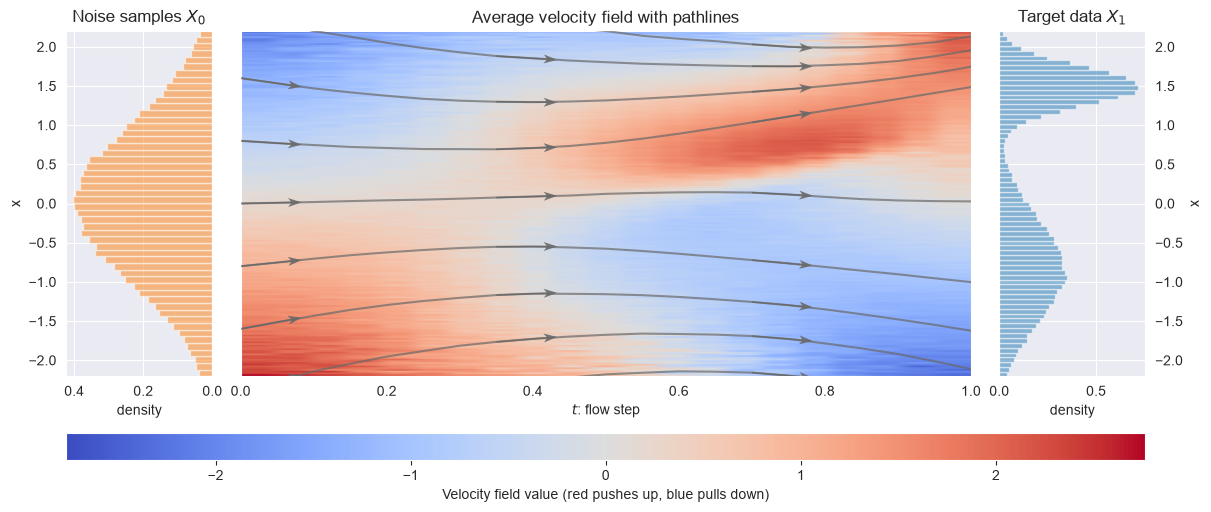

In [ ]:
# Flow field illustration, approximate the flow field by sampling a large number of reference paths over discretized flow step bins.

# Sample set of noise and target points
data_size: int = 100_000
np.random.seed(1)  # Set random seeds for reproducibility
data_x_0 = np.random.randn(data_size)
data_x_1 = mixture_sample(size=data_size)


# Set up the plot
fig, (ax1, ax2, ax3) = plt.subplots(
    1,
    3,
    figsize=(12, 5),
    gridspec_kw={"width_ratios": [1, 5, 1]},
    sharey=True,
    dpi=100,
    constrained_layout=True,
)
x_min, x_max = -2.2, 2.2  # Narrow view for flow field image
x_min_wide, x_max_wide = -3.2, 3.2  # Wide view for sample paths

# Plot the velocity field ##########################################
# Plot Noise samples X0
ax1.set_title(r"Noise samples $X_0$")
ax1.hist(
    data_x_0.flatten(),
    bins=100,
    alpha=0.5,
    label=r"Noise $\pi_0$",
    color="tab:orange",
    density=True,
    orientation="horizontal",
)
ax1.invert_xaxis()
ax1.set_ylabel("x")
ax1.set_xlabel("density")

# Plot target data distribution x1
ax3.set_title(r"Target data $X_1$")
ax3.hist(
    data_x_1.flatten(), bins=100, alpha=0.5, label=r"Target $\pi_1$", color="tab:blue", density=True, orientation="horizontal"
)
ax3.set_xlabel("density")
ax3.yaxis.set_label_position("right")
ax3.set_ylabel("x")
# Also show y-axis values on the right side
ax3.yaxis.set_visible(True)
ax3.yaxis.set_tick_params(labelright=True)

# Plot path density
n_samples = int(data_x_1.shape[0])
dt: float = 0.05  # Step size for Euler integration
n_flow_steps = int(1 / dt)
# Set up the path density histogram parameters
img_hist_size = 200
# Narrow view for flow field image
flow_field_img_bins = np.zeros((n_flow_steps + 1, img_hist_size))
flow_field_img_x_bin_edges = np.linspace(x_min, x_max, img_hist_size + 1)
# Wide view to compute the pathlines, need to be wide enough because paths can flow out of the narrow view
flow_field_for_path_bins = np.zeros((n_flow_steps + 1, img_hist_size))
flow_field_for_path_x_bin_edges = np.linspace(x_min_wide, x_max_wide, img_hist_size + 1)

# Build up the histogram of the reference paths by going over the discretized t-bins
# We're building 2 histograms:
# - `flow_field_img_bins` narrow view for the flow field image, might have NaNs if there are no samples in a bin
# - `flow_field_for_path_bins` wide view for the pathlines, avoid NaNs by setting the velocity to 0 if there are no samples in a bin
v = get_target_velocity(x_0=data_x_0, x_1=data_x_1)
for i in range(n_flow_steps + 1):
    t = np.full((n_samples,), i * dt)
    x_t = interpolate_linear(x_0=data_x_0, x_1=data_x_1, t=t)
    # Get the average velocity for each bin in the narrow view for the flow field image
    x_t_bin_indices = np.digitize(x=x_t, bins=flow_field_img_x_bin_edges[1:-1], right=False)
    counts = np.bincount(x_t_bin_indices, minlength=img_hist_size)
    sums = np.bincount(x_t_bin_indices, weights=v, minlength=img_hist_size)
    flow_field_img_bins[i] = np.divide(
        sums,
        counts,
        out=np.full(img_hist_size, np.nan, dtype=float),
        where=counts > 0,
    )

    # Get the average velocity for each bin in the wide view for the pathlines
    x_t_bin_indices_wide = np.digitize(x=x_t, bins=flow_field_for_path_x_bin_edges[1:-1], right=False)
    counts_wide = np.bincount(x_t_bin_indices_wide, minlength=img_hist_size)
    sums_wide = np.bincount(x_t_bin_indices_wide, weights=v, minlength=img_hist_size)
    flow_field_for_path_bins[i] = np.divide(
        sums_wide,
        counts_wide,
        out=np.zeros(img_hist_size, dtype=float),  # Avoid NaNs for any path sampling
        where=counts_wide > 0,
    )

# Plot the flow field
max_abs_flow_field = np.nanmax(np.abs(flow_field_img_bins))
color_norm = matplotlib.colors.TwoSlopeNorm(vmin=-max_abs_flow_field, vcenter=0.0, vmax=max_abs_flow_field)
im = ax2.imshow(
    flow_field_img_bins.T,
    aspect="auto",
    origin="lower",
    extent=[0, 1, x_min, x_max],
    cmap="coolwarm",
    norm=color_norm,
)
ax2.set_ylim(x_min, x_max)
cbar = fig.colorbar(
    im,
    ax=[ax1, ax2, ax3],
    orientation="horizontal",
    fraction=0.08,
    aspect=40,
    pad=0.04,
)
cbar.set_label("Velocity field value (red pushes up, blue pulls down)")

# Sample some paths from the mean flow field to show the pathlines
n_paths = 9
paths = np.zeros((n_flow_steps + 1, n_paths))
paths[0] = np.linspace(start=x_min_wide, stop=x_max_wide, num=n_paths)
for i in range(n_flow_steps):
    t = np.full((n_samples,), i * dt)
    x_tm1 = paths[i]
    x_tm1_bin_indices = np.digitize(x=x_tm1, bins=flow_field_for_path_x_bin_edges[1:-1], right=False)
    v = flow_field_for_path_bins[i, x_tm1_bin_indices]
    paths[i + 1] = x_tm1 + v * dt

# Plot the pathlines with arrows using quiver, following best practices
t_coords = np.linspace(0, 1, n_flow_steps + 1)
arrow_stride = 7  # space out arrows for clarity
for i in range(n_paths):
    y = paths[:, i]
    idx = np.arange(0, len(t_coords) - 1, arrow_stride)
    x0 = t_coords[idx]
    y0 = y[idx]
    u = np.diff(t_coords)[idx]
    v = np.diff(y)[idx]
    ax2.quiver(
        x0,
        y0,
        u,
        v,
        angles="xy",
        scale_units="xy",
        scale=0.6,
        units="inches",
        width=0.015,
        headwidth=6,
        headlength=9,
        headaxislength=7,
        pivot="tail",
        color="dimgray",
        alpha=0.9,
        zorder=2,
    )
    # overlay original line on top of arrows for clarity
    ax2.plot(
        t_coords,
        y,
        linestyle="-",
        color="dimgray",
        linewidth=1.5,
        alpha=0.7,
        zorder=3,
        label=f"Sample path {i + 1}",
    )


ax2.set_xlabel("$t$: flow step")
ax2.set_title("Average velocity field with pathlines")
ax2.grid(False)

In [ ]:
# Target: approximate function v(x_t, t) with FM(x_t, t)
# Linear Interpolation is -> v(x_t, t) = x_1 - x_0
# Optimization: minimize the MSE between FM(x_t, t) and v(x_t, t)